In [11]:
!pip install torch transformers

In [13]:
import pandas as pd

# Load EEG features
eeg_df = pd.read_csv('eeg_features_reordered.csv')

# Load dream reports
dreams_df = pd.read_csv('Reports_Filtered_Cleaned.csv')

# Add "DREAM:" prefix
dreams_df['dream_text'] = "DREAM: " + dreams_df['Cleaned Text']

# Align EEG with dreams by index
eeg_df = eeg_df.reset_index(drop=True)
dreams_df = dreams_df.reset_index(drop=True)

# Add the dream text to the EEG dataframe
eeg_df['dream_text'] = dreams_df['dream_text']

print(eeg_df.columns)


Index(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9',
       ...
       '122', '123', '124', '125', '126', '127', '128', '129', 'filename',
       'dream_text'],
      dtype='object', length=132)


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer

from transformers import AutoTokenizer

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')

# Set pad token to eos token
tokenizer.pad_token = tokenizer.eos_token

# Define EEG columns
EEG_COLUMNS = eeg_df.columns[:130]

# Create dataset
class EEGDreamDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.dataframe = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        eeg_features = self.dataframe.iloc[idx][EEG_COLUMNS].values.astype('float32')
        text = self.dataframe.iloc[idx]['dream_text']

        inputs = self.tokenizer(
            text, return_tensors='pt', truncation=True,
            max_length=self.max_length, padding="max_length"
        )

        return {
            'eeg': torch.tensor(eeg_features),
            'input_ids': inputs.input_ids.squeeze(0),
            'attention_mask': inputs.attention_mask.squeeze(0)
        }

# Create dataset and dataloader
dataset = EEGDreamDataset(eeg_df, tokenizer)
loader = DataLoader(dataset, batch_size=8, shuffle=True)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [15]:
import torch
import torch.nn as nn
from transformers import GPT2LMHeadModel

class EEGtoTextTransformer(nn.Module):
    def __init__(self, eeg_dim, hidden_dim=512):
        super(EEGtoTextTransformer, self).__init__()

        # Map EEG to hidden state
        self.eeg_encoder = nn.Sequential(
            nn.Linear(eeg_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )

        # Decoder (GPT-2 small)
        self.decoder = GPT2LMHeadModel.from_pretrained('gpt2')

        # Project EEG encoding into the decoder's embedding space
        self.projector = nn.Linear(hidden_dim, self.decoder.config.n_embd)

    def forward(self, eeg, input_ids, attention_mask):
        eeg_encoded = self.eeg_encoder(eeg)
        eeg_projected = self.projector(eeg_encoded)

        batch_size = eeg_projected.size(0)
        eeg_projected = eeg_projected.unsqueeze(1)  # [batch, 1, n_embd]

        inputs_embeds = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat([eeg_projected, inputs_embeds], dim=1)

        # Adjust attention mask
        new_attention_mask = torch.cat([
            torch.ones((batch_size, 1), device=attention_mask.device),
            attention_mask
        ], dim=1)

        # Adjust labels: pad one token at start
        labels = torch.cat([
            torch.full((batch_size, 1), -100, dtype=input_ids.dtype, device=input_ids.device),  # ignore index
            input_ids
        ], dim=1)

        outputs = self.decoder(
            inputs_embeds=inputs_embeds,
            attention_mask=new_attention_mask,
            labels=labels
        )

        return outputs


In [19]:
# Define epochs
total_epochs = 30   # total number of epochs
freeze_epochs = 5   # number of epochs to keep GPT-2 frozen
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
model = EEGtoTextTransformer(eeg_dim=130).to(device)
# Freeze GPT-2 decoder initially
for param in model.decoder.parameters():
    param.requires_grad = False

# Optimizer (only optimizing parameters that require grad=True)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

# Start training
for epoch in range(total_epochs):
    # Unfreeze GPT-2 after 'freeze_epochs'
    if epoch == freeze_epochs:
        print(f"Unfreezing GPT-2 at epoch {epoch}!")
        for param in model.decoder.parameters():
            param.requires_grad = True
        # Rebuild optimizer to include all parameters
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)  # smaller LR after unfreezing

    model.train()

    epoch_loss = 0.0
    for batch_idx, batch in enumerate(loader):
        eeg = batch['eeg'].to(device)
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        outputs = model(eeg, input_ids, attention_mask)
        loss = outputs.loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        # Print loss every 10 batches
        if batch_idx % 10 == 0:
            print(f"Epoch {epoch} - Batch {batch_idx} - Loss: {loss.item():.4f}")

    print(f"Epoch {epoch} finished. Average Loss: {epoch_loss/len(loader):.4f}")

print("Training completed! 🚀")


Using device: cuda


`loss_type=None` was set in the config but it is unrecognised.Using the default loss: `ForCausalLMLoss`.


Epoch 0 - Batch 0 - Loss: 7.0170
Epoch 0 - Batch 10 - Loss: 4.8957
Epoch 0 - Batch 20 - Loss: 3.8202
Epoch 0 finished. Average Loss: 4.4924
Epoch 1 - Batch 0 - Loss: 2.7761
Epoch 1 - Batch 10 - Loss: 2.8634
Epoch 1 - Batch 20 - Loss: 1.7791
Epoch 1 finished. Average Loss: 2.4261
Epoch 2 - Batch 0 - Loss: 2.6074
Epoch 2 - Batch 10 - Loss: 1.2599
Epoch 2 - Batch 20 - Loss: 1.5593
Epoch 2 finished. Average Loss: 1.8758
Epoch 3 - Batch 0 - Loss: 1.7702
Epoch 3 - Batch 10 - Loss: 1.5598
Epoch 3 - Batch 20 - Loss: 1.8248
Epoch 3 finished. Average Loss: 1.7514
Epoch 4 - Batch 0 - Loss: 1.6166
Epoch 4 - Batch 10 - Loss: 2.2385
Epoch 4 - Batch 20 - Loss: 2.0743
Epoch 4 finished. Average Loss: 1.6990
Unfreezing GPT-2 at epoch 5!
Epoch 5 - Batch 0 - Loss: 2.0331
Epoch 5 - Batch 10 - Loss: 1.4310
Epoch 5 - Batch 20 - Loss: 1.7446
Epoch 5 finished. Average Loss: 1.4719
Epoch 6 - Batch 0 - Loss: 0.8404
Epoch 6 - Batch 10 - Loss: 0.7499
Epoch 6 - Batch 20 - Loss: 1.0158
Epoch 6 finished. Average Loss

In [20]:
save_path = "eeg_gpt2_dream_model.pth"
torch.save(model.state_dict(), save_path)
print(f"✅ Model saved at {save_path}")

✅ Model saved at eeg_gpt2_dream_model.pth


In [21]:
def generate_dream_with_prefix(model, eeg_sample, tokenizer, device, max_length=150):
    model.eval()

    eeg_sample = torch.tensor(eeg_sample, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        eeg_encoded = model.eeg_encoder(eeg_sample)
        eeg_projected = model.projector(eeg_encoded)
    eeg_projected = eeg_projected.unsqueeze(1)

    start_text = "DREAM: I "
    input_ids = tokenizer.encode(start_text, return_tensors='pt').to(device)

    with torch.no_grad():
        input_embeds = model.decoder.transformer.wte(input_ids)

    full_embeds = torch.cat([eeg_projected, input_embeds], dim=1)

    attention_mask = torch.ones(full_embeds.size()[:-1], dtype=torch.long, device=device)

    generated_ids = model.decoder.generate(
        inputs_embeds=full_embeds,
        attention_mask=attention_mask,
        max_length=max_length,
        do_sample=True,                  # <-- important for randomness
        top_k=50,                         # <-- sampling top 50 words
        top_p=0.95,                       # <-- nucleus sampling
        temperature=0.7,                  # <-- randomness control
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id
    )

    dream_text = tokenizer.decode(generated_ids[0], skip_special_tokens=True)

    return dream_text


In [22]:
sample_eeg = eeg_df.iloc[0][EEG_COLUMNS].values.astype('float32')
dream = generate_dream_with_prefix(model, sample_eeg, tokenizer, device, max_length=150)
print(dream)


͡° , I don't know if I was dreaming or if I was just imagining it, but I was thinking about.. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking about .. I don't know what I was imagining, but I was thinking


##Metric

In [23]:
pip install bert-score


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.3 MB/s eta 0:00:00


In [24]:
# 1. Generate a dream from your model
sample_eeg = eeg_df.iloc[0][EEG_COLUMNS].values.astype('float32')
dream_generated = generate_dream_with_prefix(model, sample_eeg, tokenizer, device, max_length=150)

# 2. Get the corresponding real dream from the dataset
dream_reference = eeg_df.iloc[0]['dream_text']  # or 'Cleaned Text' if you prefer

# 3. Evaluate with BERTScore
from bert_score import score

P, R, F1 = score([dream_generated], [dream_reference], lang="en", verbose=True)

print(f"Precision: {P.mean().item():.4f}")
print(f"Recall: {R.mean().item():.4f}")
print(f"F1 Score: {F1.mean().item():.4f}")


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

calculating scores...
computing bert embedding.


  0%|          | 0/1 [00:00<?, ?it/s]

computing greedy matching.


  0%|          | 0/1 [00:00<?, ?it/s]

done in 0.15 seconds, 6.74 sentences/sec
Precision: 0.8416
Recall: 0.8355
F1 Score: 0.8386


In [25]:
!pip install diffusers transformers accelerate


In [26]:
from diffusers import StableDiffusionPipeline
import torch
import matplotlib.pyplot as plt


In [34]:
from diffusers import StableDiffusionPipeline
import torch

# Correct loading of Dreamshaper 8
pipe = StableDiffusionPipeline.from_pretrained(
    "Lykon/dreamshaper-8",
    torch_dtype=torch.float16,
).to("cuda")


model_index.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/transformers/models/clip/feature_extraction_clip.py:28: FutureWarning: The class CLIPFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use CLIPImageProcessor instead.
  warnings.warn(


In [35]:
def generate_dream_image(dream_script, output_path="dream_image.png"):
    pipe.enable_attention_slicing()  # Saves memory (important in Colab)

    with torch.autocast("cuda"):
        image = pipe(dream_script, guidance_scale=8.5).images[0]

    # Save the image
    image.save(output_path)
    print(f" Image saved as {output_path}")

    # Display the image
    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.title(dream_script, fontsize=10)
    plt.show()

    return image


Generated Dream Script:
 thought about going to a bar and having a beer, and then going to bed.


  0%|          | 0/50 [00:00<?, ?it/s]

✅ Image saved as dream1.png


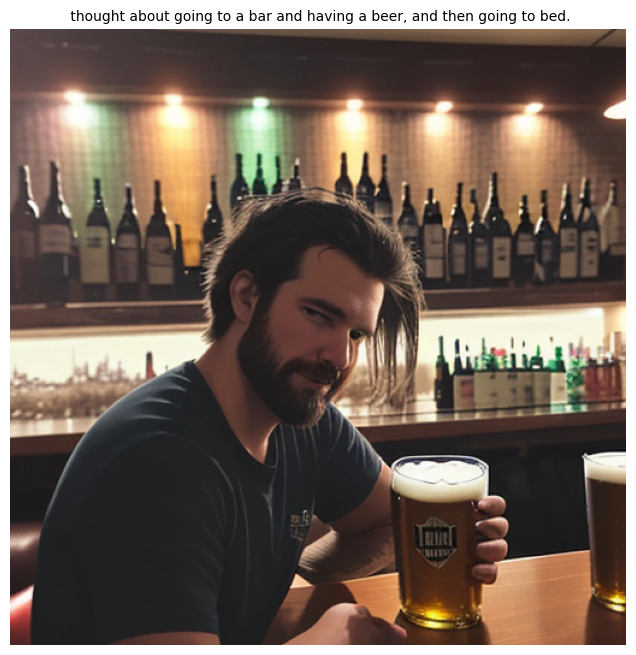

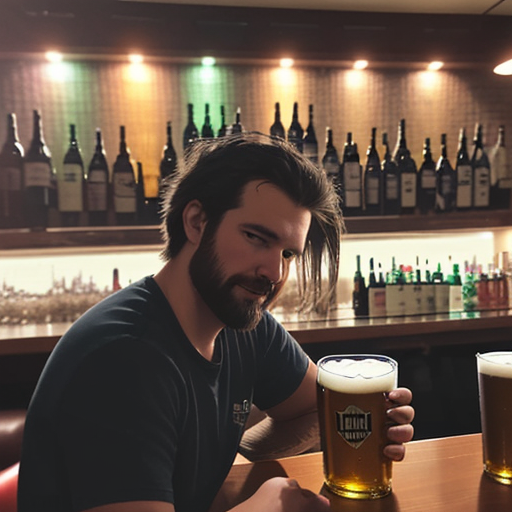

In [39]:
# Step 1: Generate dream script
dream_script = generate_dream_with_prefix(model, sample_eeg, tokenizer, device)

print(f"Generated Dream Script:\n{dream_script}")

# Step 2: Generate dream image
generate_dream_image(dream_script, output_path="dream1.png")
